⚠️ No se encontró ningún archivo CSV. Por favor sube tu archivo a continuación:


Saving module6_sample_sensor_history.csv to module6_sample_sensor_history.csv
Timestamp source: ORIGINAL
Expected interval: 60 seconds


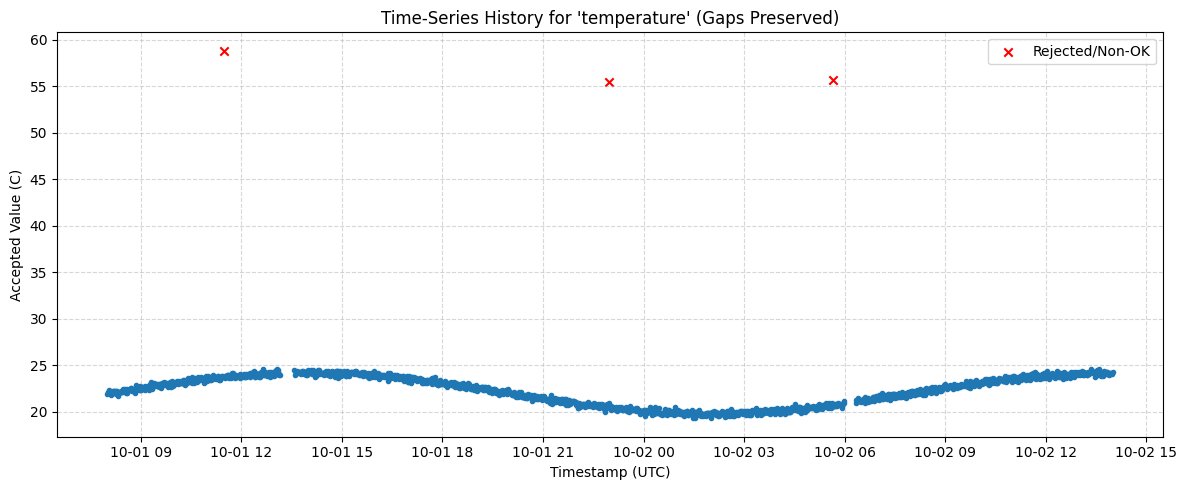

✅ Test 1 Passed: Database logging row counts match exactly.
✅ Test 2 Passed: Gap detection & completeness range validated.


In [2]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io

# ============================================================
# 1. CARGA AUTOMÁTICA O MANUAL DE DATOS
# ============================================================
DB_FILE = "module6_sensor_history.db"

# Intentar buscar archivos CSV en el entorno actual
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]

if csv_files:
    # Usar el primer CSV disponible en la carpeta
    chosen_file = csv_files[0]
    print(f"✅ Archivo encontrado y cargado: {chosen_file}")
    df_raw = pd.read_csv(chosen_file)
else:
    # Si no existe en el entorno, solicitar subirlo mediante el widget de Colab
    print("⚠️ No se encontró ningún archivo CSV. Por favor sube tu archivo a continuación:")
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df_raw = pd.read_csv(io.BytesIO(uploaded[file_name]))

df_raw.columns = [str(c).strip().lower().replace(" ", "_") for c in df_raw.columns]

# Timestamp processing (Original vs Reconstructed)
if "timestamp" in df_raw.columns:
    df_raw["timestamp"] = pd.to_datetime(df_raw["timestamp"], utc=True)
    TIMESTAMP_SOURCE = "ORIGINAL"
    EXPECTED_INTERVAL_SECONDS = 60
else:
    START_TIME = pd.Timestamp("2026-10-01 12:00:00", tz="UTC")
    df_raw["sample_number"] = df_raw.get("sample_number", np.arange(1, len(df_raw) + 1))
    df_raw["timestamp"] = START_TIME + pd.to_timedelta((df_raw["sample_number"] - 1) * 2, unit="s")
    TIMESTAMP_SOURCE = "RECONSTRUCTED"
    EXPECTED_INTERVAL_SECONDS = 2

print(f"Timestamp source: {TIMESTAMP_SOURCE}")
print(f"Expected interval: {EXPECTED_INTERVAL_SECONDS} seconds")

# ============================================================
# 2. TRANSFORMACIÓN A FORMATO LARGO (LONG-FORM)
# ============================================================
SENSOR_MAPPING = {
    "temperature": ("temperature_c", "temperature_status", "C"),
    "humidity": ("humidity_percent", "humidity_status", "%"),
    "light": ("light_raw", "light_status", "raw"),
    "distance": ("distance_cm", "distance_status", "cm"),
    "potentiometer": ("potentiometer_percent", "potentiometer_status", "%")
}

history_records = []
for idx, row in df_raw.iterrows():
    sn = row.get("sample_number", idx + 1)
    ts = row["timestamp"].isoformat()

    for sensor, (val_col, stat_col, unit) in SENSOR_MAPPING.items():
        if val_col in df_raw.columns:
            val = row[val_col]
            stat = str(row.get(stat_col, "OK")).strip().upper() if stat_col in df_raw.columns else "OK"
            accepted = val if stat == "OK" and not pd.isna(val) else np.nan

            history_records.append({
                "sample_number": int(sn),
                "timestamp": ts,
                "sensor_name": sensor,
                "raw_value": val,
                "accepted_value": accepted,
                "status": stat,
                "unit": unit,
                "timestamp_source": TIMESTAMP_SOURCE
            })

history_df = pd.DataFrame(history_records)

# ============================================================
# 3. SQLITE DATABASE CREATION & LOGGING
# ============================================================
if Path(DB_FILE).exists():
    Path(DB_FILE).unlink()

conn = sqlite3.connect(DB_FILE)
conn.execute("""
CREATE TABLE sensor_readings (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    sample_number INTEGER NOT NULL,
    timestamp TEXT NOT NULL,
    sensor_name TEXT NOT NULL,
    raw_value REAL,
    accepted_value REAL,
    status TEXT NOT NULL,
    unit TEXT NOT NULL,
    timestamp_source TEXT NOT NULL
)
""")

history_df.to_sql("sensor_readings", conn, if_exists="append", index=False)
conn.execute("CREATE INDEX idx_sensor_time ON sensor_readings(sensor_name, timestamp)")
conn.commit()

# ============================================================
# 4. TIME-RANGE QUERIES & EXPORTS
# ============================================================
latest_ts_str = conn.execute("SELECT MAX(timestamp) FROM sensor_readings").fetchone()[0]
latest_ts = pd.Timestamp(latest_ts_str)

cutoff_1h = (latest_ts - pd.Timedelta(hours=1)).isoformat()
last_hour_df = pd.read_sql_query("SELECT * FROM sensor_readings WHERE timestamp >= ? ORDER BY timestamp", conn, params=[cutoff_1h])

cutoff_1d = (latest_ts - pd.Timedelta(days=1)).isoformat()
last_day_df = pd.read_sql_query("SELECT * FROM sensor_readings WHERE timestamp >= ? ORDER BY timestamp", conn, params=[cutoff_1d])

full_history_df = pd.read_sql_query("SELECT * FROM sensor_readings ORDER BY timestamp", conn)

last_hour_df.to_csv("last_hour_report.csv", index=False)
last_day_df.to_csv("last_day_report.csv", index=False)
full_history_df.to_csv("full_history_report.csv", index=False)

# ============================================================
# 5. GAP DETECTION & COMPLETENESS REPORTING
# ============================================================
gap_threshold = EXPECTED_INTERVAL_SECONDS * 1.5
summary_list = []

for sensor, group in full_history_df.groupby("sensor_name"):
    group = group.copy()
    group["dt"] = pd.to_datetime(group["timestamp"])
    group = group.sort_values("dt")
    group["delta_sec"] = group["dt"].diff().dt.total_seconds()

    gaps = group[group["delta_sec"] > gap_threshold]
    total_span_sec = (group["dt"].max() - group["dt"].min()).total_seconds()
    expected_readings = int(round(total_span_sec / EXPECTED_INTERVAL_SECONDS)) + 1 if len(group) else 0
    received_readings = len(group)
    missing_readings = max(expected_readings - received_readings, 0)
    completeness_pct = (received_readings / expected_readings * 100) if expected_readings else 0
    max_gap = gaps["delta_sec"].max() if len(gaps) else 0.0

    summary_list.append({
        "sensor": sensor,
        "expected": expected_readings,
        "received": received_readings,
        "missing": missing_readings,
        "completeness_percent": round(completeness_pct, 2),
        "gap_count": len(gaps),
        "largest_gap_seconds": max_gap
    })

completeness_df = pd.DataFrame(summary_list)
completeness_df.to_csv("gap_completeness_report.csv", index=False)

# ============================================================
# 6. TIME-SERIES PLOT PRESERVING GAPS
# ============================================================
def plot_sensor_without_smoothing(sensor_name):
    g = full_history_df[full_history_df["sensor_name"] == sensor_name].copy()
    g["dt"] = pd.to_datetime(g["timestamp"])
    g = g.sort_values("dt")
    g["delta"] = g["dt"].diff().dt.total_seconds()

    g["segment"] = (g["delta"] > gap_threshold).cumsum()

    plt.figure(figsize=(12, 5))
    for _, segment_df in g.groupby("segment"):
        plt.plot(segment_df["dt"], segment_df["accepted_value"], color="tab:blue", marker=".", linewidth=1.5)

    bad_data = g[g["status"] != "OK"]
    if len(bad_data) > 0:
        plt.scatter(bad_data["dt"], bad_data["raw_value"], color="red", marker="x", label="Rejected/Non-OK")

    plt.title(f"Time-Series History for '{sensor_name}' (Gaps Preserved)")
    plt.xlabel("Timestamp (UTC)")
    plt.ylabel(f"Accepted Value ({g['unit'].iloc[0]})")
    plt.grid(True, linestyle="--", alpha=0.5)
    if len(bad_data) > 0:
        plt.legend()
    plt.tight_layout()
    plt.savefig(f"{sensor_name}_honest_timeseries.png")
    plt.show()

plot_sensor_without_smoothing(full_history_df["sensor_name"].iloc[0])

# ============================================================
# 7. AUTOMATED TESTS
# ============================================================
db_row_count = conn.execute("SELECT COUNT(*) FROM sensor_readings").fetchone()[0]
assert db_row_count == len(history_df), f"Fail: {db_row_count} DB vs {len(history_df)} DF"
print("✅ Test 1 Passed: Database logging row counts match exactly.")

assert (completeness_df["completeness_percent"] >= 0).all() and (completeness_df["completeness_percent"] <= 100).all(), "Fail: Invalid completeness range"
print("✅ Test 2 Passed: Gap detection & completeness range validated.")

conn.close()